# Neutrino-Induced Charm Production: Slow Rescaling Model vs Measurements

Comparison of the **Georgi–Politzer / Barnett Slow Rescaling Model** with historical inclusive experimental measurements from **CHORUS** (2011) and **E531** (1988) on nuclear emulsion targets.

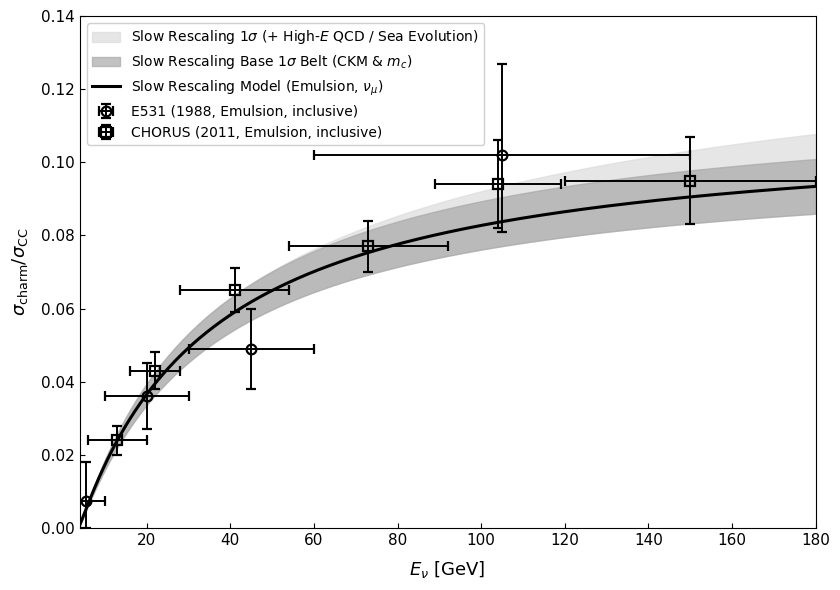

In [5]:
import csv
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Resolve CSV location relative to notebook directory or repo root
csv_path = Path("../scripts/diagnostics/measurements/neutrino_charm_cross_section_ratio_vs_enu.csv")
if not csv_path.exists():
    csv_path = Path("scripts/diagnostics/measurements/neutrino_charm_cross_section_ratio_vs_enu.csv")

# 1. Parse historical measurements (inclusive charm production on emulsion)
records = []
with open(csv_path, "r", encoding="utf-8-sig") as f:
    clean_lines = [line for line in f if not line.strip().startswith("#")]
    reader = csv.DictReader(clean_lines)
    for row in reader:
        if row.get("channel", "").strip().lower() != "inclusive":
            continue
        records.append({
            "exp": row["experiment"].strip(),
            "x": float(row["E_nu_GeV"]),
            "dx_lo": float(row["dx_low"]),
            "dx_hi": float(row["dx_high"]),
            "y": float(row["ratio"]),
            "dy_lo": float(row["dy_low"]),
            "dy_hi": float(row["dy_high"]),
        })

# 2. Slow Rescaling Model (Nuclear Emulsion target, nu_mu CC)
m_p = 0.938272
m_c = 1.2729
sigma_m_c = 0.0045
e_thresh = ((m_p + m_c)**2 - m_p**2) / (2.0 * m_p) + 1.50

# Nuclear Emulsion composition (<Z/A> ~ 0.467)
f_p = 0.467
f_n = 1.0 - f_p
u_val_p, d_val_p, sea_q = 0.285, 0.130, 0.035
s_quark = 0.55 * sea_q
d_target = f_p * d_val_p + f_n * u_val_p + sea_q

v_cd, v_cs = 0.22503, 0.97345
r_inf = (v_cd**2 * d_target + v_cs**2 * s_quark) / (d_target + s_quark + (1.0 / 3.0) * sea_q)

alpha = 1.15
e_scale = 28.0
sigma_ethresh = ((m_p + m_c) / m_p) * sigma_m_c
rel_base = 0.08

# Grid covering the measurement range [4, 180] GeV
e_pts = np.linspace(4.0, 180.0, 500)
y_cen = np.zeros_like(e_pts)
y_in_lo = np.zeros_like(e_pts)
y_in_hi = np.zeros_like(e_pts)
y_out_hi = np.zeros_like(e_pts)

for i, x in enumerate(e_pts):
    if x <= e_thresh:
        continue
    kin = ((1.0 - e_thresh / x)**alpha) * (x / (x + e_scale))
    y = r_inf * kin
    dy_dethresh = r_inf * alpha * ((1.0 - e_thresh / x)**(alpha - 1.0)) * (-1.0 / (x + e_scale))
    sigma_kin = abs(dy_dethresh * sigma_ethresh)

    # Inner band: base kinematics + CKM/PDF normalization
    sigma_inner = math.sqrt((kin * rel_base * r_inf)**2 + sigma_kin**2)

    # Outer band: high-E QCD evolution (gluon fusion and strange sea growth)
    rel_high_e = 0.28 * math.log(max(1.0, x / 40.0)) / math.log(1000.0 / 40.0)
    tot_rel = math.sqrt(rel_base**2 + rel_high_e**2)
    sigma_outer_up = math.sqrt((kin * r_inf * tot_rel)**2 + sigma_kin**2)

    y_cen[i] = y
    y_in_lo[i] = max(0.0, y - sigma_inner)
    y_in_hi[i] = y + sigma_inner
    y_out_hi[i] = y + sigma_outer_up

# 3. Plotting
fig, ax = plt.subplots(figsize=(8.5, 6.0))

# Error bands: two shades of grey
ax.fill_between(
    e_pts, y_in_lo, y_out_hi,
    color="#dcdcdc", label=r"Slow Rescaling $1\sigma$ (+ High-$E$ QCD / Sea Evolution)", zorder=1, alpha=0.7
)
ax.fill_between(
    e_pts, y_in_lo, y_in_hi,
    color="#a8a8a8", label=r"Slow Rescaling Base $1\sigma$ Belt (CKM & $m_c$)", zorder=2, alpha=0.7
)

# Continuous black line for central model
ax.plot(
    e_pts, y_cen,
    color="black", lw=2.2, label=r"Slow Rescaling Model (Emulsion, $\nu_\mu$)", zorder=3
)

# Black markers for historical experimental data
labels_map = {
    "E531": "E531 (1988, Emulsion, inclusive)",
    "CHORUS": "CHORUS (2011, Emulsion, inclusive)"
}
for exp, marker in [("E531", "o"), ("CHORUS", "s")]:
    pts = [r for r in records if r["exp"] == exp]
    if not pts:
        continue
    x = [p["x"] for p in pts]
    y = [p["y"] for p in pts]
    x_err = [[p["dx_lo"] for p in pts], [p["dx_hi"] for p in pts]]
    y_err = [[p["dy_lo"] for p in pts], [p["dy_hi"] for p in pts]]
    ax.errorbar(
        x, y, xerr=x_err, yerr=y_err,
        fmt=marker, mfc="none", mec="black", mew=1.6, markersize=7,
        ecolor="black", elinewidth=1.4, capsize=3.5, capthick=1.2,
        label=labels_map[exp], zorder=4
    )

ax.set_xlim(4.0, 180.0)
ax.set_ylim(0.0, 0.14)
ax.set_xlabel(r"$E_\nu$ [GeV]", fontsize=13, labelpad=8)
ax.set_ylabel(r"$\sigma_{\mathrm{charm}} / \sigma_{\mathrm{CC}}$", fontsize=13, labelpad=8)
ax.tick_params(axis="both", which="major", labelsize=11, direction="in")
# ax.grid(True, which="major", linestyle="--", alpha=0.45, color="gray")

leg = ax.legend(loc="upper left", fontsize=10.0, frameon=True, framealpha=0.92, facecolor="white")
leg.get_frame().set_linewidth(1.0)

plt.tight_layout()
plt.show()
